<a href="https://colab.research.google.com/github/belgaa-a/EksploracjaDanych/blob/main/AW_zajecia5_1211.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Dane:**
kaggle.com/c/house-prices-advanced-regression-techniques


In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_theme(style="whitegrid")
df = pd.read_csv('train.csv')

Jaka jest zmienna docelowa (ang. target variable), którą chcemy przewidywać?


In [ ]:
target = 'SalePrice'
print(df[target].head())

Jakie rodzaje zmiennych są w zbiorze (liczbowe, kategoryczne, tekstowe)?

In [25]:
zmienne_liczbowe = df.select_dtypes(include=['int64', 'float64']).columns
zmienne_kategoryczne = df.select_dtypes(include=['object', 'category']).columns

print("Zmienne liczbowe:")
print(list(zmienne_liczbowe))

print("\nZmienne kategoryczne:")
print(list(zmienne_kategoryczne))

print("\nLiczba zmiennych liczbowych:", len(zmienne_liczbowe))
print("Liczba zmiennych kategorycznych:", len(zmienne_kategoryczne))


Zmienne liczbowe:
['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']

Zmienne kategoryczne:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'Fireplac

Wyświetl podstawowe statystyki opisowe (df.describe()).
Sprawdź typy danych wszystkich kolumn (df.dtypes).

In [26]:
df.describe()
df.dtypes
df.describe(include='all')

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
count,1460.000000,1460.000000,1460,1201.000000,1460.000000,1460,91,1460,1460,1460,1460,1460,1460,1460,1460,1460,1460,1460.000000,1460.000000,1460.000000,1460.000000,1460,1460,1460,1460,588,1452.000000,1460,1460,1460,1423,1423,1422,1423,1460.000000,1422,1460.000000,1460.000000,1460.000000,1460,1460,1460,1459,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460,1460.000000,1460,1460.000000,770,1379,1379.000000,1379,1460.000000,1460.000000,1379,1379,1460,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,7,281,54,1460.000000,1460.000000,1460.000000,1460,1460,1460.000000
unique,NaN,NaN,5,NaN,NaN,2,2,4,4,2,5,3,25,9,8,5,8,NaN,NaN,NaN,NaN,6,8,15,16,3,NaN,4,5,6,4,4,4,6,NaN,6,NaN,NaN,NaN,6,5,2,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,NaN,7,NaN,5,6,NaN,3,NaN,NaN,5,5,3,NaN,NaN,NaN,NaN,NaN,NaN,3,4,4,NaN,NaN,NaN,9,6,NaN
top,NaN,NaN,RL,NaN,NaN,Pave,Grvl,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,Norm,1Fam,1Story,NaN,NaN,NaN,NaN,Gable,CompShg,VinylSd,VinylSd,BrkFace,NaN,TA,TA,PConc,TA,TA,No,Unf,NaN,Unf,NaN,NaN,NaN,GasA,Ex,Y,SBrkr,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TA,NaN,Typ,NaN,Gd,Attchd,NaN,Unf,NaN,NaN,TA,TA,Y,NaN,NaN,NaN,NaN,NaN,NaN,Gd,MnPrv,Shed,NaN,NaN,NaN,WD,Normal,NaN
freq,NaN,NaN,1151,NaN,NaN,1454,50,925,1311,1459,1052,1382,225,1260,1445,1220,726,NaN,NaN,NaN,NaN,1141,1434,515,504,445,NaN,906,1282,647,649,1311,953,430,NaN,1256,NaN,NaN,NaN,1428,741,1365,1334,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,735,NaN,1360,NaN,380,870,NaN,605,NaN,NaN,1311,1326,1340,NaN,NaN,NaN,NaN,NaN,NaN,3,157,49,NaN,NaN,NaN,1267,1198,NaN
mean,730.500000,56.897260,NaN,70.049958,10516.828082,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.099315,5.575342,1971.267808,1984.865753,NaN,NaN,NaN,NaN,NaN,103.685262,NaN,NaN,NaN,NaN,NaN,NaN,NaN,443.639726,NaN,46.549315,567.240411,1057.429452,NaN,NaN,NaN,NaN,1162.626712,346.992466,5.844521,1515.463699,0.425342,0.057534,1.565068,0.382877,2.866438,1.046575,NaN,6.517808,NaN,0.613014,NaN,NaN,1978.506164,NaN,1.767123,472.980137,NaN,NaN,NaN,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,NaN,NaN,NaN,43.489041,6.321918,2007.815753,NaN,NaN,180921.195890
std,421.610009,42.300571,NaN,24.284752,9981.264932,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.382997,1.112799,30.202904,20.645407,NaN,NaN,NaN,NaN,NaN,181.066207,NaN,NaN,NaN,NaN,NaN,NaN,NaN,456.098091,NaN,161.319273,441.866955,438.705324,NaN,NaN,NaN,NaN,386.587738,436.528436,48.623081,525.480383,0.518911,0.238753,0.550916,0.502885,0.815778,0.220338,NaN,1.625393,NaN,0.644666,NaN,NaN,24.689725,NaN,0.747315,213.804841,NaN,NaN,NaN,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,NaN,NaN,NaN,496.123024,2.703626,1.328095,NaN,NaN,79442.502883
min,1.000000,20.000000,NaN,21.000000,1300.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,1.000000,1872.000000,1950.000000,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,334.000000,0.000000,0.000000,334.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,2.000000,NaN,0.000000,NaN,NaN,1900.000000,N

Sprawdź braki danych — i ustal, co oznaczają (data_description.txt).

In [27]:
braki = df.isnull().sum()

procent_brakow = (df.isnull().sum() / len(df)) * 100

braki_danych = pd.DataFrame({
    'Liczba braków': braki,
    'Procent braków (%)': procent_brakow
})

braki_danych = braki_danych[braki_danych['Liczba braków'] > 0]
braki_danych = braki_danych.sort_values(
    by='Liczba braków', ascending=False
)

display(braki_danych)

kolumny_na = [
    'Alley',
    'BsmtQual',
    'BsmtCond',
    'BsmtExposure',
    'BsmtFinType1',
    'BsmtFinType2',
    'FireplaceQu',
    'GarageType',
    'GarageFinish',
    'GarageQual',
    'GarageCond',
    'PoolQC',
    'Fence',
    'MiscFeature'
]

for kolumna in kolumny_na:
    if kolumna in df.columns:
        print(f"{kolumna}: {df[kolumna].isnull().sum()} braków")

,Liczba braków,Procent braków (%)
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


Alley: 1369 braków
BsmtQual: 37 braków
BsmtCond: 37 braków
BsmtExposure: 38 braków
BsmtFinType1: 37 braków
BsmtFinType2: 38 braków
FireplaceQu: 690 braków
GarageType: 81 braków
GarageFinish: 81 braków
GarageQual: 81 braków
GarageCond: 81 braków
PoolQC: 1453 braków
Fence: 1179 braków
MiscFeature: 1406 braków


Przygotuj wykresy podobne do tych z wykładu.

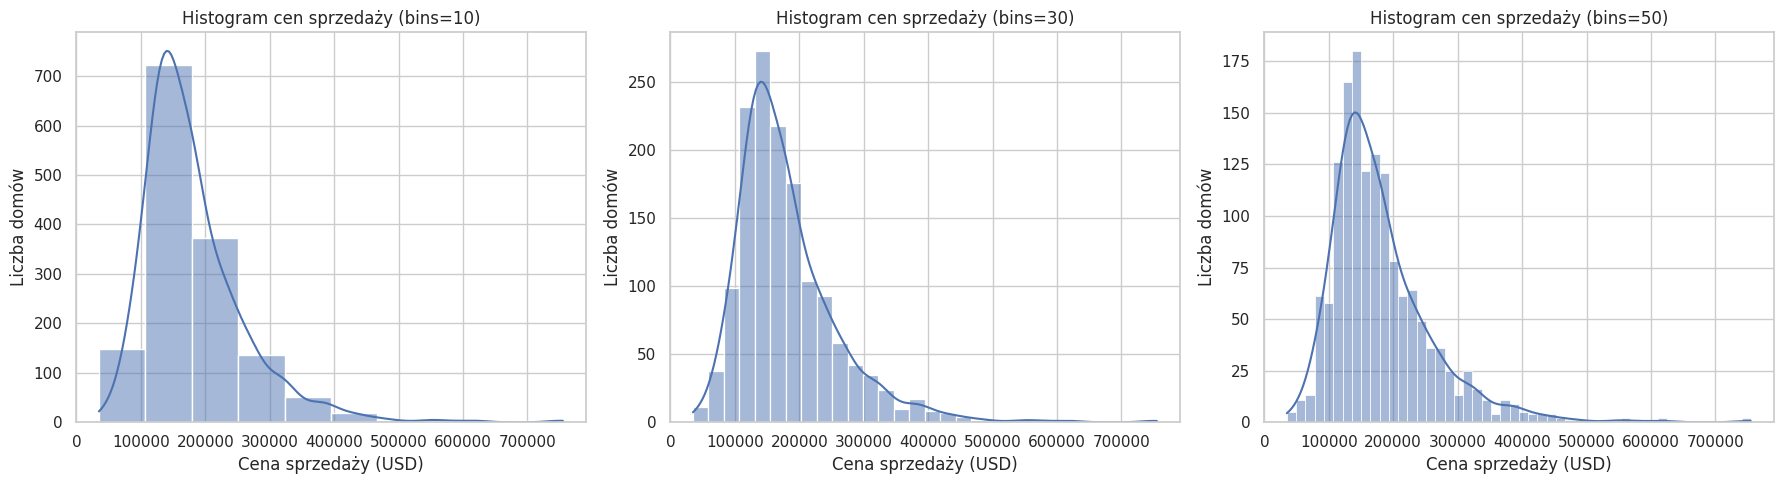

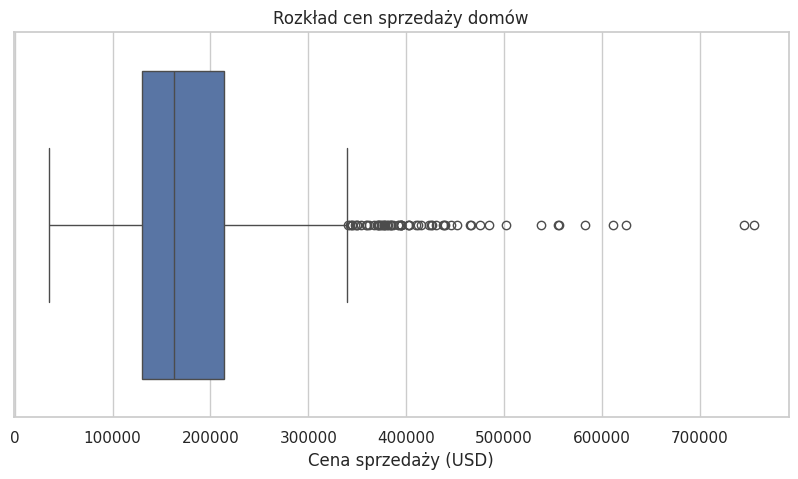

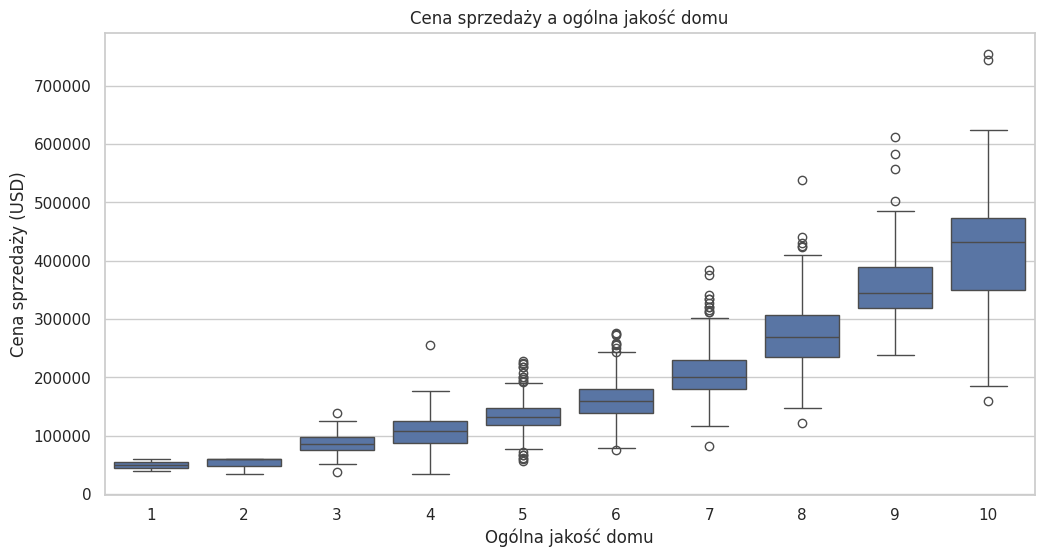

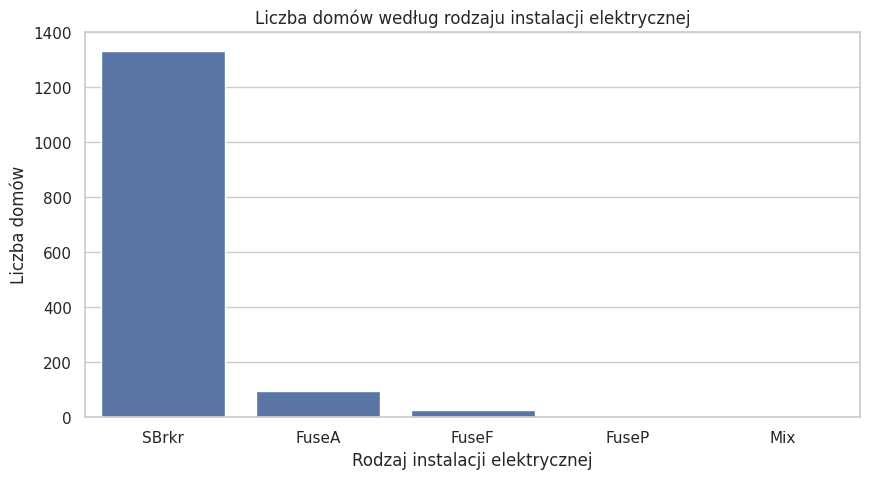

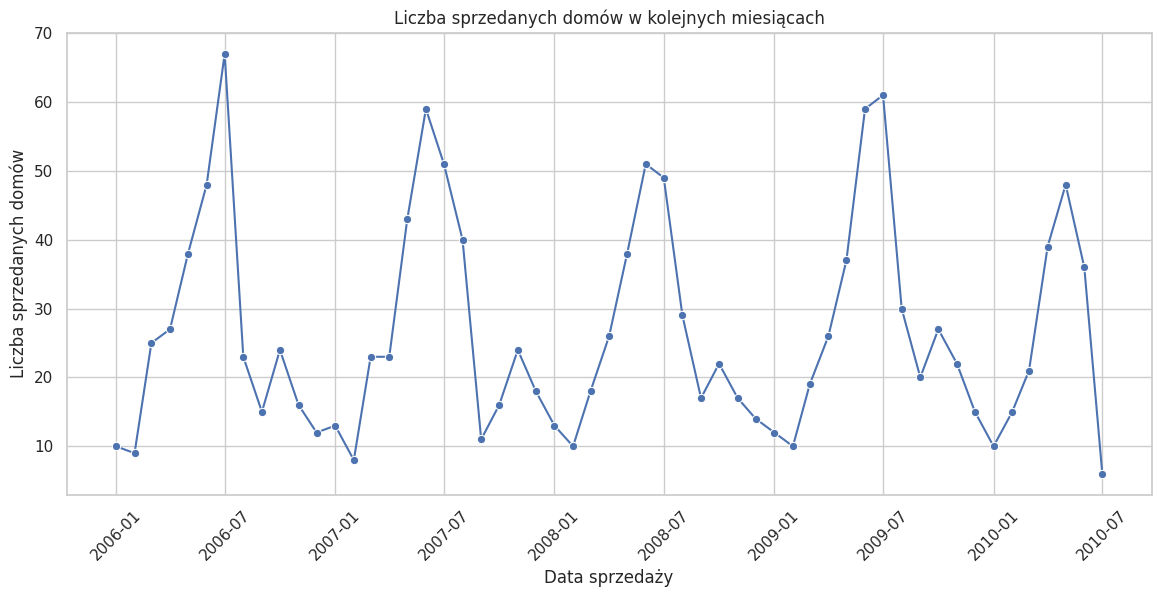

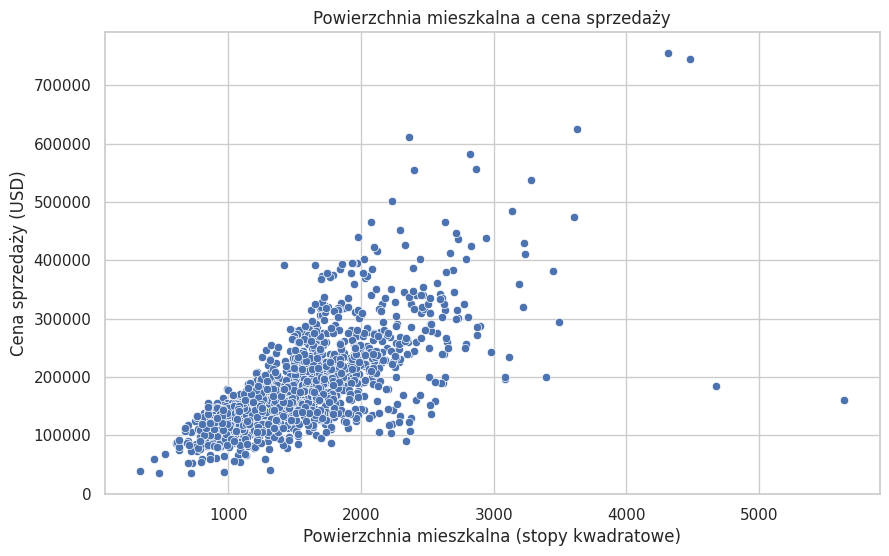

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, bins in zip(axes, [10, 30, 50]):
    sns.histplot(df['SalePrice'], bins=bins, kde=True, ax=ax)
    ax.set_title(f'Histogram cen sprzedaży (bins={bins})')
    ax.set_xlabel('Cena sprzedaży (USD)')
    ax.set_ylabel('Liczba domów')

plt.tight_layout()

plt.figure(figsize=(10, 5))
sns.boxplot(x=df['SalePrice'])

plt.title('Rozkład cen sprzedaży domów')
plt.xlabel('Cena sprzedaży (USD)')


plt.figure(figsize=(12, 6))

sns.boxplot(data=df, x='OverallQual', y='SalePrice')

plt.title('Cena sprzedaży a ogólna jakość domu')
plt.xlabel('Ogólna jakość domu')
plt.ylabel('Cena sprzedaży (USD)')


plt.figure(figsize=(10, 5))

sns.countplot(data=df, x='Electrical', order=df['Electrical'].value_counts().index)

plt.title('Liczba domów według rodzaju instalacji elektrycznej')
plt.xlabel('Rodzaj instalacji elektrycznej')
plt.ylabel('Liczba domów')


sprzedaz = df.groupby(['YrSold', 'MoSold']).size().reset_index(name='Liczba domów')

sprzedaz['Data'] = pd.to_datetime(
    sprzedaz['YrSold'].astype(str) + '-' +
    sprzedaz['MoSold'].astype(str) + '-01'
)

plt.figure(figsize=(14, 6))

sns.lineplot(data=sprzedaz, x='Data', y='Liczba domów', marker='o')

plt.title('Liczba sprzedanych domów w kolejnych miesiącach')
plt.xlabel('Data sprzedaży')
plt.ylabel('Liczba sprzedanych domów')
plt.xticks(rotation=45)


plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x='GrLivArea', y='SalePrice')

plt.title('Powierzchnia mieszkalna a cena sprzedaży')
plt.xlabel('Powierzchnia mieszkalna (stopy kwadratowe)')
plt.ylabel('Cena sprzedaży (USD)')
plt.show()

Jaki jest rozkład cen?

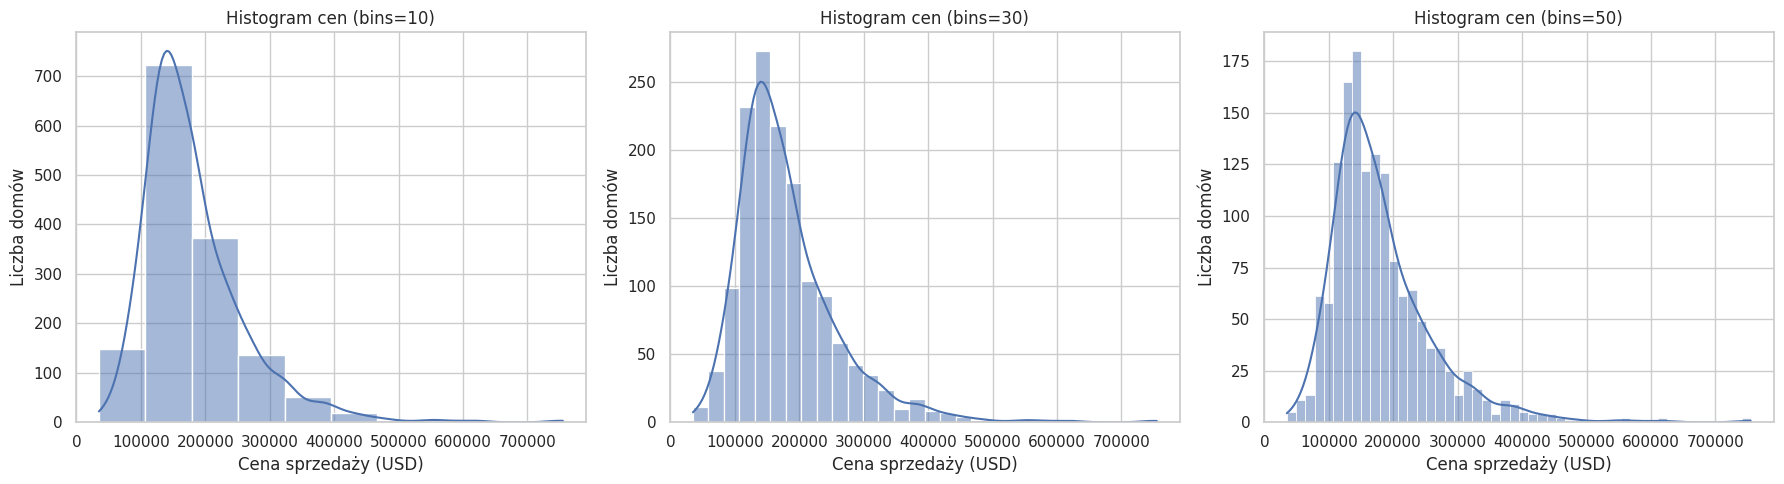

Skośność rozkładu: 1.8828757597682129


In [35]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, bins in zip(axes, [10, 30, 50]):
    sns.histplot(df['SalePrice'], bins=bins, kde=True, ax=ax)
    ax.set_title(f'Histogram cen (bins={bins})')
    ax.set_xlabel('Cena sprzedaży (USD)')
    ax.set_ylabel('Liczba domów')

plt.tight_layout()
plt.show()
print("Skośność rozkładu:", df['SalePrice'].skew())

Histogram cen: poeksperymentuj z liczbą przedziałów (bins = 10, 30, 50). Czy rozkład jest skośny?

Zmiana liczby przedziałów nie wpływa na skośność, większość domów została sprzedana w niższych cenach.

Czy są wartości odstające?

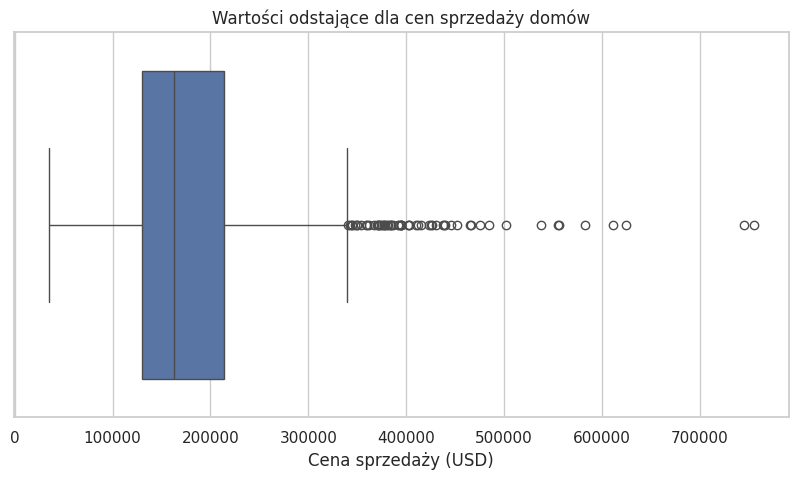

In [33]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df['SalePrice'])

plt.title('Wartości odstające dla cen sprzedaży domów')
plt.xlabel('Cena sprzedaży (USD)')
plt.show()

Wartości odstające mogą oznaczać nieruchomości o wysokim standardzie, dużej powierzchni lub dobrej lokalizacji. Nie muszą być błędem, mogą przedstawiać rzeczywiste transakcje dotyczące luksusowych domów.

Jaka jest średnia i mediana ceny?

In [36]:
ceny = df['SalePrice']

Q1 = ceny.quantile(0.25)
Q3 = ceny.quantile(0.75)
IQR = Q3 - Q1

statystyki = pd.DataFrame({
    'Miara': ['Minimum', 'Maksimum', 'Średnia', 'Mediana', 'Q1 (25%)', 'Q3 (75%)', 'IQR'],
    'Wartość (USD)': [
        ceny.min(),
        ceny.max(),
        ceny.mean(),
        ceny.median(),
        Q1,
        Q3,
        IQR
    ]
})

display(statystyki.round(2))

,Miara,Wartość (USD)
0,Minimum,34900.0
1,Maksimum,755000.0
2,Średnia,180921.2
3,Mediana,163000.0
4,Q1 (25%),129975.0
5,Q3 (75%),214000.0
6,IQR,84025.0


Czy ceny mają rozkład normalny? (wskazówka: czy histogram jest symetryczny?)

Ceny sprzedaży domów nie mają rozkładu normalnego. Histogram jest niesymetryczny i wykazuje prawoskośność.

Hipoteza do sprawdzenia: „Większe domy są droższe”.
- Znajdź zmienne związane z powierzchnią (wskazówka: szukaj „Area” i „SF” w nazwach kolumn).
- Narysuj wykres punktowy: powierzchnia mieszkalna vs cena.
Czy zależność jest wyraźna? Czy jest liniowa?
Czy są dziwne obserwacje? Kim one są?


- Czy powierzchnia działki (LotArea) ma taki sam wpływ jak powierzchnia domu?
- Narysuj wykresy punktowe dla 2–3 rodzajów powierzchni — która ma najsilniejszy związek z ceną?

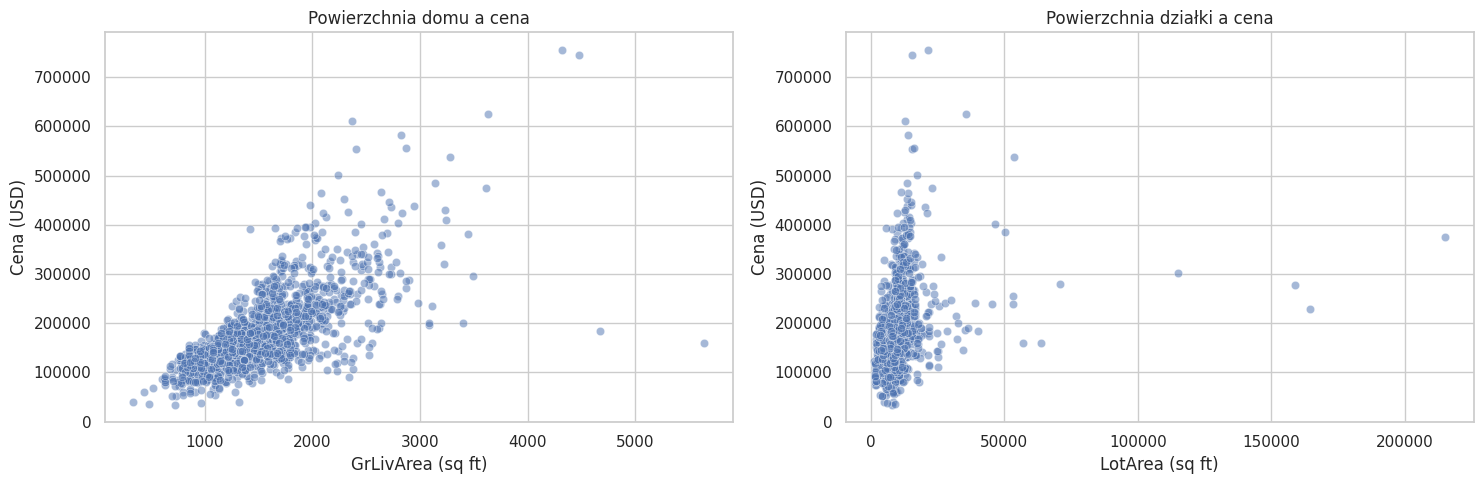

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.scatterplot(data=df, x='GrLivArea', y='SalePrice', alpha=0.5, ax=axes[0])
axes[0].set_title('Powierzchnia domu a cena')
axes[0].set_xlabel('GrLivArea (sq ft)')
axes[0].set_ylabel('Cena (USD)')

sns.scatterplot(data=df, x='LotArea', y='SalePrice', alpha=0.5, ax=axes[1])
axes[1].set_title('Powierzchnia działki a cena')
axes[1].set_xlabel('LotArea (sq ft)')
axes[1].set_ylabel('Cena (USD)')

plt.tight_layout()
plt.show()

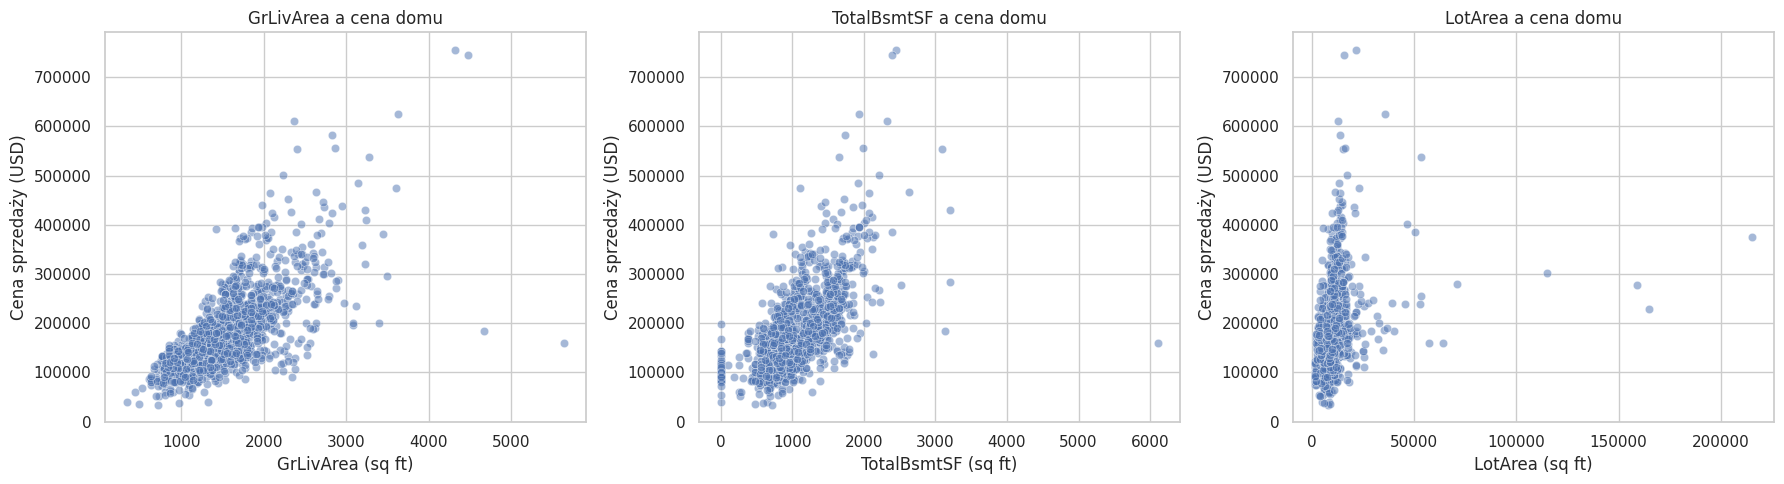

Korelacja z ceną sprzedaży:


,Korelacja
GrLivArea,0.708624
TotalBsmtSF,0.613581
LotArea,0.263843


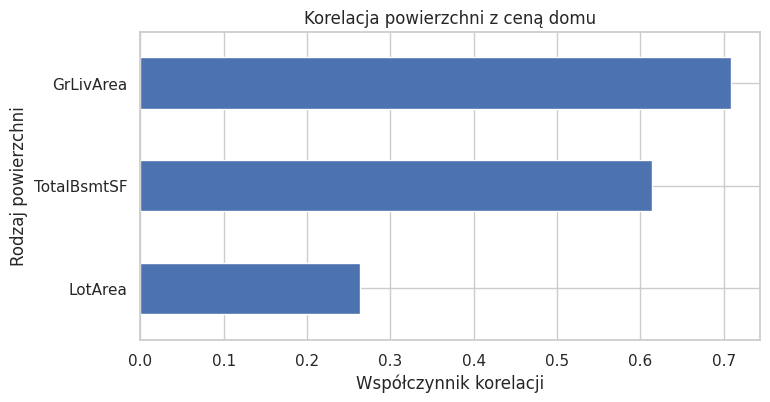

In [46]:
zmienne = ['GrLivArea', 'TotalBsmtSF', 'LotArea']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, kolumna in zip(axes, zmienne):
    sns.scatterplot(
        data=df,
        x=kolumna,
        y='SalePrice',
        alpha=0.5,
        ax=ax
    )
    ax.set_title(f'{kolumna} a cena domu')
    ax.set_xlabel(f'{kolumna} (sq ft)')
    ax.set_ylabel('Cena sprzedaży (USD)')

plt.tight_layout()
plt.show()

korelacje = df[zmienne + ['SalePrice']].corr()['SalePrice'].drop('SalePrice')

print("Korelacja z ceną sprzedaży:")
display(korelacje.sort_values(ascending=False).to_frame('Korelacja'))

plt.figure(figsize=(8, 4))

korelacje.sort_values().plot(kind='barh')

plt.title('Korelacja powierzchni z ceną domu')
plt.xlabel('Współczynnik korelacji')
plt.ylabel('Rodzaj powierzchni')
plt.show()

Najsilniejszy związek z ceną sprzedaży powinna wykazywać powierzchnia mieszkalna (GrLivArea). Zależność jest dodatnia – większe domy zazwyczaj osiągają wyższe ceny.

Powierzchnia piwnicy (TotalBsmtSF) również wykazuje dodatnią zależność z ceną, natomiast powierzchnia działki (LotArea) ma zazwyczaj słabszy związek. Oznacza to, że wielkość samego budynku jest bardziej związana z jego ceną niż wielkość działki.